### 1. Εισαγωγή βιβλιοθηκών και φόρτωση των επεξεργασμένων datasets

In [13]:
# Εισαγωγή των απαραίτητων βιβλιοθηκών και φόρτωση των 3 καθαρών CSV αρχείων
# από τον φάκελο data/processed/ για έλεγχο διαστάσεων (γραμμές x στήλες).

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'

PROCESSED_DIR = os.path.join("..", "data", "processed")
FIGURES_DIR = os.path.join("..", "outputs", "figures")
os.makedirs(FIGURES_DIR, exist_ok=True)

results = pd.read_csv(os.path.join(PROCESSED_DIR, "clean_results.csv"))
entries = pd.read_csv(os.path.join(PROCESSED_DIR, "clean_entries.csv"))
records = pd.read_csv(os.path.join(PROCESSED_DIR, "clean_records.csv"))

print(f"1. Περάσματα (clean_results.csv): {results.shape[0]} εγγραφές, {results.shape[1]} στήλες")
print(f"2. Συμμετοχές (clean_entries.csv): {entries.shape[0]} εγγραφές, {entries.shape[1]} στήλες")
print(f"3. Ιστορικά Ρεκόρ (clean_records.csv): {records.shape[0]} εγγραφές, {records.shape[1]} στήλες")

1. Περάσματα (clean_results.csv): 14096 εγγραφές, 72 στήλες
2. Συμμετοχές (clean_entries.csv): 2941 εγγραφές, 21 στήλες
3. Ιστορικά Ρεκόρ (clean_records.csv): 2541 εγγραφές, 17 στήλες


### 2. Έλεγχος Πληρότητας ανά Αγώνα (Συμμετοχές vs Περάσματα)

In [14]:
# Διασταύρωση του πίνακα Συμμετοχών (Entries) με τον πίνακα Περασμάτων (Results) ανά Αγώνα.
# Εντοπίζει: (α) ποιες εγγραφές ανήκουν σε ΔΟΚΙΜΕΣ, και (β) αγώνες που έχουν μόνο
# δηλωμένες συμμετοχές αλλά 0 καταγεγραμμένα περάσματα (όπως ο (κατά την ώρα των testings) 3ος Πρωταθληματικός - ααΑγώνα=4).

entries_per_race = (
    entries.groupby(['Race_UID', 'ααΑγώνα', 'Ημερομηνία_Αγώνα', 'ΠΙΣΤΑ', 'Σχόλια'], dropna=False)['ααΣυμμετοχής']
    .count()
    .rename('Συμμετοχές (Entries)')
)

# Χρησιμοποιεί το Race_UID (π.χ. Drag2026_R1) αντί για το ααΑγώνα (1), ώστε να μην μπερδεύονται
# οι αγώνες διαφορετικών ετών όταν ενωθούν πολλές βάσεις.
runs_per_race = (
    results.groupby('Race_UID')['ααΕπίδοσης']
    .count()
    .rename('Σύνολο Περασμάτων (Results)')
)

clean_runs_per_race = (
    results[results['Is_Clean_Pass'] == True]
    .groupby('Race_UID')['ααΕπίδοσης']
    .count()
    .rename('Καθαρά Περάσματα (Is_Clean_Pass)')
)

race_audit = (
    entries_per_race.reset_index()
    .merge(runs_per_race, on='Race_UID', how='left')
    .merge(clean_runs_per_race, on='Race_UID', how='left')
    .fillna({'Σύνολο Περασμάτων (Results)': 0, 'Καθαρά Περάσματα (Is_Clean_Pass)': 0}) # οι αγώνες που έχουν μόνο entries - χωρίς περάσματα/runs θα βγάλουν null/NaN οπότε το κάνουμε 0.
)

race_audit['Σύνολο Περασμάτων (Results)'] = race_audit['Σύνολο Περασμάτων (Results)'].astype(int)
race_audit['Καθαρά Περάσματα (Is_Clean_Pass)'] = race_audit['Καθαρά Περάσματα (Is_Clean_Pass)'].astype(int)

display(race_audit)

,Race_UID,ααΑγώνα,Ημερομηνία_Αγώνα,ΠΙΣΤΑ,Σχόλια,Συμμετοχές (Entries),Σύνολο Περασμάτων (Results),Καθαρά Περάσματα (Is_Clean_Pass)
0,Drag2021_22_R01,1,2021-07-10,ΔΟΚΙΜΕΣ,NaN,7,33,0
1,Drag2021_22_R02,2,2021-06-06,ΣΕΡΡΕΣ,Προπόνηση και 2ος Πρωταθληματικός,165,1067,907
2,Drag2021_22_R03,3,2021-07-11,ΣΕΡΡΕΣ,DragDay αυτοκινητων\r\n3ος Πρωταθληματικός μοτ...,123,568,490
3,Drag2021_22_R04,4,2021-10-17,ΣΕΡΡΕΣ,4ος Πρωταθληματικός,130,407,333
4,Drag2021_22_R05,5,2022-04-16,ΣΕΡΡΕΣ,1ος Πρωταθληματικός,145,572,467
5,Drag2021_22_R06,6,2022-06-26,ΣΕΡΡΕΣ,3ος πρωταθληματικός. Τριήμερος,128,798,666
6,Drag2021_22_R07,7,2022-09-18,ΣΕΡΡΕΣ,4ος πρωταθληματικός,119,714,598
7,Drag2023_R01,1,2023-04-21,ΔΟΚΙΜΕΣ,NaN,5,63,0
8,Drag2023_R02,2,2023-07-02,ΣΕΡΡΕΣ,2ος Πρωταθληματικός,170,919,800
9,Drag2023_R03,3,2023-09-17,ΣΕΡΡΕΣ,3ος Αυτοκινήτων\r\n4ος Μοτοσυκλετών,94,474,416


### 3. Έλεγχος "Ορφανών" Εγγραφών

In [15]:
# Έλεγχος περασμάτων στον πίνακα Results που δεν συνδέονται με κανέναν οδηγό/συμμετοχή
# (ααΣυμμετοχής == 0). Επιβεβαιώνει ότι πρόκειται αποκλειστικά για εικονικές εγγραφές
# ΠΡΕΠΕΙ ο κωδικός 'εγκυρη' να είναι "Αναγκαστ.Bye" (Εγκυρη == -5): στα Eliminations όταν ένας οδηγός τρέχει μόνος του (Μονό/Bye Run).

orphan_passes = results[results['ααΣυμμετοχής'] == 0]

print(f"1. Πλήθος περασμάτων με ααΣυμμετοχής == 0: {len(orphan_passes)}")

print("\n2. Κατανομή ανά κωδικό εγκυρότητας (αναμένεται μόνο -5 = Αναγκαστ.Bye):")
print(orphan_passes['Εγκυρη'].value_counts(dropna=False))

n_with_time = (orphan_passes['Χρόνος400_sec'] > 0).sum()
print(f"\n3. Περάσματα χωρίς συμμετοχή που έχουν πραγματικό χρόνο 400m (αναμένεται 0): {n_with_time}")

print("\n4. Αναλυτικός πίνακας των περασμάτων χωρίς συμμετοχή:")
display(orphan_passes[['ααΕπίδοσης', 'Race_UID', 'Περιγραφή', 'Εγκυρη', 'Περιγραφή_valid', 'Χρόνος400_sec']])

1. Πλήθος περασμάτων με ααΣυμμετοχής == 0: 21

2. Κατανομή ανά κωδικό εγκυρότητας (αναμένεται μόνο -5 = Αναγκαστ.Bye):
Εγκυρη
-5.0    20
 0.0     1
Name: count, dtype: int64

3. Περάσματα χωρίς συμμετοχή που έχουν πραγματικό χρόνο 400m (αναμένεται 0): 0

4. Αναλυτικός πίνακας των περασμάτων χωρίς συμμετοχή:


,ααΕπίδοσης,Race_UID,Περιγραφή,Εγκυρη,Περιγραφή_valid,Χρόνος400_sec
2935,13250,Drag2021_22_R06,Ημιτελικοί,-5.0,Αναγκαστ.Bye,0.0
3272,12532,Drag2021_22_R05,2ος Γύρος,-5.0,Αναγκαστ.Bye,0.0
3956,14061,Drag2021_22_R07,Ημιτελικοί,-5.0,Αναγκαστ.Bye,0.0
4033,14103,Drag2021_22_R07,Ημιτελικοί,-5.0,Αναγκαστ.Bye,0.0
4964,806,Drag2023_R02,2ος Γύρος,-5.0,Αναγκαστ.Bye,0.0
6779,2602,Drag2023_R05,2ος Γύρος,-5.0,Αναγκαστ.Bye,0.0
7104,2962,Drag2023_R06,Τελικός,-5.0,Αναγκαστ.Bye,0.0
8682,4273,Drag2023_R08,2ος Γύρος,-5.0,Αναγκαστ.Bye,0.0
9417,5300,Drag2023_R09,Ημιτελικοί,-5.0,Αναγκαστ.Bye,0.0
9419,5302,Drag2023_R09,Τελικός,-5.0,Αναγκαστ.Bye,0.0


### 4. Ανάλυση Κατανομής των Κωδικών Εγκυρότητας (Valid) & Ερμηνεία του ΝΑΑγώνα

In [16]:
# Κατανομή όλων των περασμάτων ανά Κωδικό Εγκυρότητας (Εγκυρη / Περιγραφή_valid)
# και έλεγχος του κωδικού 1.0 ('ΝΑΑγώνα' = Νικητής Άνευ Αγώνα σε κόντρες Eliminations).

validity_counts = (
    results.groupby(['Εγκυρη', 'Περιγραφή_valid'], dropna=False)['ααΕπίδοσης']
    .count()
    .reset_index(name='Πλήθος')
)
validity_counts['Ποσοστό (%)'] = (validity_counts['Πλήθος'] / len(results) * 100).round(2)
validity_counts = validity_counts.sort_values(by='Πλήθος', ascending=False)

display(validity_counts)

# Check the Sample για Επιβεβαίωση ότι το Εγκυρη == 1.0 ('ΝΑΑγώνα') έχει μηδενικούς χρόνους (0.0s) και ΑποτέλεσμαΚόντρας == 1 (Νίκη)
na_agona_sample = results[results['Εγκυρη'] == 1.0][
    ['ααΕπίδοσης', 'Περιγραφή', 'Ονοματεπώνυμο', 'ΠεριγραφήΚατηγορίας', 'Χρόνος18_sec', 'Χρόνος400_sec', 'ΑποτέλεσμαΚόντρας']
].head(10)
print("\nΔείγμα εγγραφών με Εγκυρη == 1.0 (ΝΑΑγώνα - Νικητής Άνευ Αγώνα):")
display(na_agona_sample)

,Εγκυρη,Περιγραφή_valid,Πλήθος,Ποσοστό (%)
6,0.0,Έγκυρος,12520,88.82
0,-6.0,ΌριοΧρόνου,426,3.02
5,-1.0,Ακυρος,330,2.34
3,-3.0,Εγκατέλειψε,287,2.04
4,-2.0,Δεν προσήλθε,251,1.78
7,1.0,ΝΑΑγώνα,141,1.00
2,-4.0,ΆκΔιαδρομή,96,0.68
8,NaN,NaN,25,0.18
1,-5.0,Αναγκαστ.Bye,20,0.14



Δείγμα εγγραφών με Εγκυρη == 1.0 (ΝΑΑγώνα - Νικητής Άνευ Αγώνα):


,ααΕπίδοσης,Περιγραφή,Ονοματεπώνυμο,ΠεριγραφήΚατηγορίας,Χρόνος18_sec,Χρόνος400_sec,ΑποτέλεσμαΚόντρας
412,10987,1ος Γύρος,ΣΙΔΗΡΟΠΟΥΛΟΣ ΠΑΥΛΟΣ,SUPER PRO<200>,0.0,0.0,1
430,11005,1ος Γύρος,ΛΑΜΠΡΟΠΟΥΛΟΣ ΓΙΑΝΝΗΣ,SUPERSTREET<200,0.0,0.0,1
444,11019,1ος Γύρος,ΜΑΡΤΖΑΚΛΗΣ ΓΙΑΝΝΗΣ,REAL STREET<200>,0.0,0.0,1
462,11037,Τελικός,ΚΑΡΑΦΟΥΛΙΔΗΣ ΔΗΜΗΤΡΙΟΣ,AT1,0.0,0.0,1
493,11068,2ος Γύρος,ΓΚΑΪΝΤΑΤΖΗΣ ΘΕΟΦΙΛΟΣ,INDEX 11,0.0,0.0,1
1063,10903,1ος Γύρος,ΒΙΝΤΟΣ ΣΤΑΥΡΟΣ,PRO STREET1,0.0,0.0,1
1931,12661,Ημιτελικοί,ΠΑΠΑΔΟΠΟΥΛΟΣ ΦΩΤΗΣ,REAL STREET<200>,0.0,0.0,1
2011,11936,Τελικός,ΜΙΧΟΣ ΣΤΕΦΑΝΟΣ,ΒΤ1,0.0,0.0,1
2015,11940,1ος Γύρος,ΨΑΘΑ ΦΩΤΕΙΝΗ,INDEX 11,0.0,0.0,1
3045,13255,1ος Γύρος,ΜΠΑΧΤΣΕΒΑΝΙΔΟΥ ΜΑΡΙΑ,INDEX 9,0.0,0.0,1


### 5. Έλεγχος Διαρροής Φίλτρων (Waterfall Audit) και Στατιστική Σύγκριση Πριν & Μετά τον Καθαρισμό (Raw vs Is_Clean_Pass)
- #### **SOS - ΠΑΡΑΔΟΧΗ:** Περάσματα με SENSOR GLITCHES (π.χ. error φωτοκυττάρων μόνο στον χρόνο 18μ. ή ταχύτητα 400μ.) γίνονται FILTER OUT ακόμη κι αν το υπόλοιπο πέρασμα μετρήθηκε κανονικά!

In [17]:
# Έλεγχος Διαρροής Φίλτρων (Waterfall Audit) και Στατιστική Σύγκριση Πριν & Μετά τον Καθαρισμό (Raw vs Clean).
# 1. Δείχνει πόσα περάσματα κόβονται σε κάθε βήμα του φίλτρου Is_Clean_Pass.
# 2. Συγκρίνει τα βασικά στατιστικά (Count, Mean, Median, Std, Min, Max) πριν και μετά τον καθαρισμό.
# (Τα αποτελέσματα δείχνουν πώς οι εγκαταλείψεις (π.χ. ET 69.7s) παραμορφώνουν τον μέσο όρο και την τυπική απόκλιση)

raw_400 = results[(results['Απόσταση_Κατηγορίας_m'] == 400) & (results['Χρόνος400_sec'] > 0)]
clean_400 = results[(results['Απόσταση_Κατηγορίας_m'] == 400) & (results['Is_Clean_Pass'] == True)]

raw_200 = results[(results['Απόσταση_Κατηγορίας_m'] == 200) & (results['Χρόνος200_sec'] > 0)]
clean_200 = results[(results['Απόσταση_Κατηγορίας_m'] == 200) & (results['Is_Clean_Pass'] == True)]

# 1. Waterfall Audit (Υπολογισμός υπολοίπου περασμάτων σε κάθε βήμα)
def build_waterfall(df, dist):
    et_col = 'Χρόνος400_sec' if dist == 400 else 'Χρόνος200_sec'
    spd_col = 'Ταχύτητα400' if dist == 400 else 'Ταχύτητα200'
    et_bounds = (6.5, 20.0) if dist == 400 else (3.5, 14.0)
    spd_bounds = (80, 320) if dist == 400 else (60, 280)

    # steps
    s0 = df
    s1 = s0[s0['ΠΙΣΤΑ'] != 'ΔΟΚΙΜΕΣ']
    s2 = s1[s1['Εγκυρη'] == 0]
    s3 = s2[s2['Χρόνος18_sec'].between(0.8, 3.5)]
    s4 = s3[s3[et_col].between(*et_bounds)]
    s5 = s4[s4[spd_col].between(*spd_bounds)]

    return [len(s0), len(s1), len(s2), len(s3), len(s4), len(s5)]

wf_400 = build_waterfall(raw_400, 400)
wf_200 = build_waterfall(raw_200, 200)

# Έλεγχος συγχρονισμού: τα περάσματα που μένουν μετά το τελευταίο βήμα του waterfall (wf[-1])
# πρέπει να ισούνται με τα περάσματα που έχουν Is_Clean_Pass == True. (Το [-1] σημαίνει "το τελευταίο στοιχείο της λίστας")
assert wf_400[-1] == len(clean_400) and wf_200[-1] == len(clean_200), \
    "Το waterfall δεν συμφωνεί με το Is_Clean_Pass: ελέγξτε τα όρια σε script και notebook"

waterfall_df = pd.DataFrame({
    'Βήμα Φιλτραρίσματος': [
        '0. Raw Περάσματα (Χρόνος Τερματισμού > 0s)',
        '1. Αφαίρεση Δοκιμών (ΠΙΣΤΑ != ΔΟΚΙΜΕΣ)',
        '2. Έγκυρα Αγωνιστικά Περάσματα (Εγκυρη == 0)',
        '3. Φίλτρο 18m / 60ft (0.8s έως 3.5s)',
        '4. Φίλτρο Χρόνου Τερματισμού (400m: 6.5-20s | 200m: 3.5-14s)',
        '5. Φίλτρο Ταχύτητας Εξόδου (400m: 80-320 | 200m: 60-280 km/h) [Clean]'
    ],
    'Υπόλοιπο 400m': wf_400,
    'Κόπηκαν 400m': [0] + list(np.diff(wf_400) * -1),
    'Υπόλοιπο 200m': wf_200,
    'Κόπηκαν 200m': [0] + list(np.diff(wf_200) * -1)
    # np.diff(wf) δίνει [επόμενο - προηγούμενο] για κάθε ζεύγος διαδοχικών βημάτων (αρνητικοί αριθμοί,
    # αφού το υπόλοιπο μειώνεται). Το * -1 τους κάνει θετικούς, δηλαδή πόσα περάσματα κόπηκαν σε κάθε βήμα.
    # Το [0] μπαίνει μπροστά γιατί το βήμα 0 (Raw) δεν κόβει τίποτα, ώστε η λίστα να έχει 6 τιμές όπως οι γραμμές.
})

print("1. Έλεγχος Διαρροής ανά Βήμα Φιλτραρίσματος (Waterfall Audit):")
display(waterfall_df)

# 2. Απλή Στατιστική Σύγκριση Πριν (Raw) vs Μετά (Clean)
def calc_stats(series):
    return pd.Series({
        'Count (Πλήθος)': series.count(), # δεν μπορεί να γίνει int γιατί κάθε στήλη ενός DataFrame πρέπει να έχει έναν ενιαίο τύπο δεδομένων.
        'Mean (Μέσος Όρος)': series.mean(),
        'Median (Διάμεσος)': series.median(),
        'Std (Τυπ. Απόκλιση)': series.std(),
        'Min (Ελάχιστο)': series.min(),
        'Max (Μέγιστο)': series.max()
    }).round(3)

stats_comparison = pd.DataFrame({
    '400m ET Raw (s)': calc_stats(raw_400['Χρόνος400_sec']),
    '400m ET Clean (s)': calc_stats(clean_400['Χρόνος400_sec']),
    '200m ET Raw (s)': calc_stats(raw_200['Χρόνος200_sec']),
    '200m ET Clean (s)': calc_stats(clean_200['Χρόνος200_sec']),
    'Ταχύτητα 400m Raw (km/h)': calc_stats(raw_400['Ταχύτητα400']),
    'Ταχύτητα 400m Clean (km/h)': calc_stats(clean_400['Ταχύτητα400']),
    'Ταχύτητα 200m Raw (km/h)': calc_stats(raw_200['Ταχύτητα200']),
    'Ταχύτητα 200m Clean (km/h)': calc_stats(clean_200['Ταχύτητα200'])
})

print("\n2. Στατιστική Σύγκριση Πριν (Raw) vs Μετά (Clean):")
display(stats_comparison)

1. Έλεγχος Διαρροής ανά Βήμα Φιλτραρίσματος (Waterfall Audit):


,Βήμα Φιλτραρίσματος,Υπόλοιπο 400m,Κόπηκαν 400m,Υπόλοιπο 200m,Κόπηκαν 200m
0,0. Raw Περάσματα (Χρόνος Τερματισμού > 0s),10741,0,1938,0
1,1. Αφαίρεση Δοκιμών (ΠΙΣΤΑ != ΔΟΚΙΜΕΣ),10612,129,1938,0
2,2. Έγκυρα Αγωνιστικά Περάσματα (Εγκυρη == 0),10019,593,1865,73
3,3. Φίλτρο 18m / 60ft (0.8s έως 3.5s),9884,135,1855,10
4,4. Φίλτρο Χρόνου Τερματισμού (400m: 6.5-20s | ...,9695,189,1850,5
5,5. Φίλτρο Ταχύτητας Εξόδου (400m: 80-320 | 200...,9599,96,1840,10



2. Στατιστική Σύγκριση Πριν (Raw) vs Μετά (Clean):


,400m ET Raw (s),400m ET Clean (s),200m ET Raw (s),200m ET Clean (s),Ταχύτητα 400m Raw (km/h),Ταχύτητα 400m Clean (km/h),Ταχύτητα 200m Raw (km/h),Ταχύτητα 200m Clean (km/h)
Count (Πλήθος),10741.000,9599.000,1938.000,1840.000,10741.000,9599.000,1938.000,1840.000
Mean (Μέσος Όρος),11.674,10.963,5.808,5.692,198.294,204.626,201.927,203.642
Median (Διάμεσος),10.787,10.549,5.377,5.352,206.380,208.730,214.505,215.100
Std (Τυπ. Απόκλιση),4.176,1.940,1.632,1.149,51.143,42.704,40.397,37.785
Min (Ελάχιστο),2.580,8.004,4.532,4.532,0.000,80.460,16.230,60.310
Max (Μέγιστο),69.725,19.969,31.697,13.941,431.480,285.450,352.460,260.570


### 6. Οπτικοποίηση Καθαρισμού & Αποθήκευση Γραφήματος στο *"outputs/figures/"*

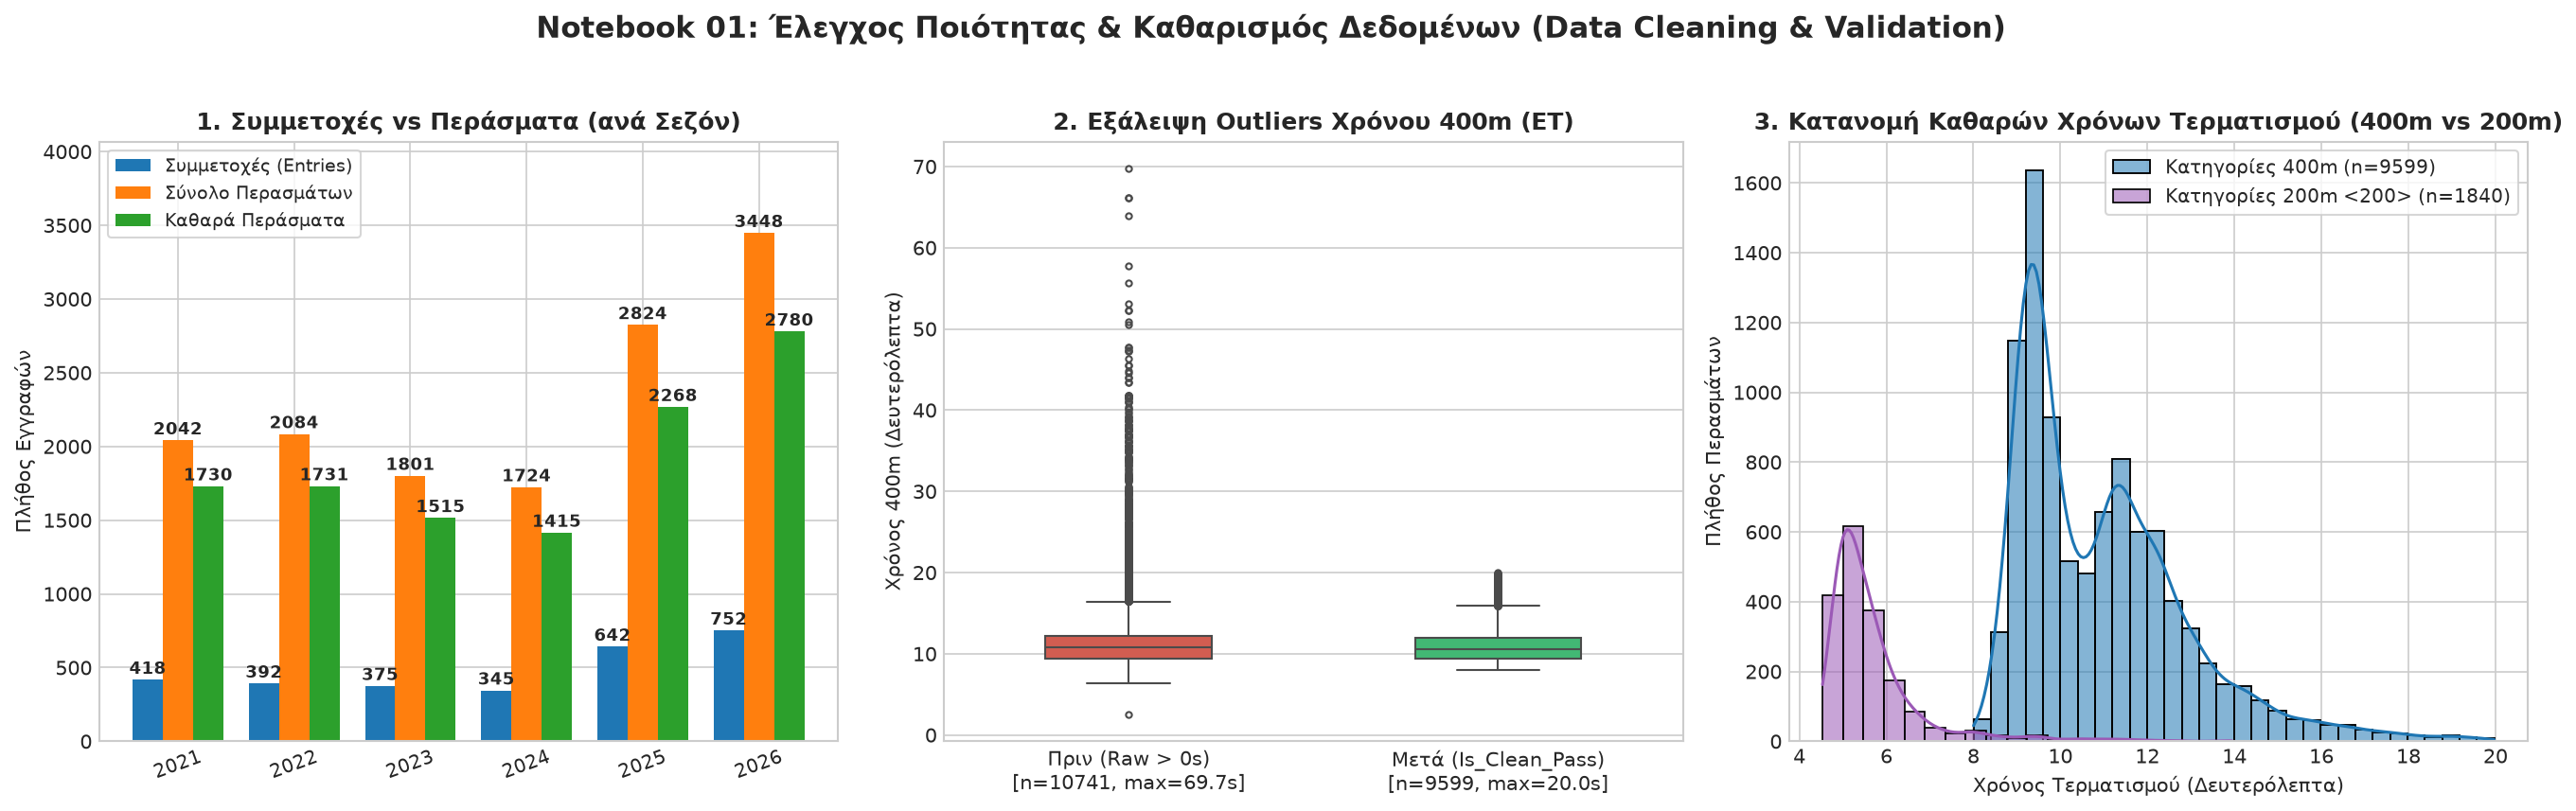

Το γράφημα αποθηκεύτηκε στο: ..\outputs\figures\01_data_cleaning_validation.png


In [18]:
# Δημιουργία τριπλού γραφήματος ελέγχου ποιότητας δεδομένων (δυναμικό για 1 ή πολλές βάσεις):
# (1) Συμμετοχές vs Περάσματα (ανά Αγώνα αν υπάρχει 1 βάση, ή ανά Σεζόν/DB_Source αν υπάρχουν πολλές βάσεις),
# (2) Boxplot εξάλειψης Outliers στα 400m, και (3) Ιστόγραμμα κατανομής καθαρών χρόνων 400m vs 200m (<200>).
# Αποθηκεύει την εικόνα στον φάκελο outputs/figures/01_data_cleaning_validation.png.


# Αυτόματη επιλογή ομαδοποίησης: ανά Αγώνα (Race_UID) για 1 βάση, ή ανά Σεζόν (DB_Source) για >1 βάσεις
# group_col = 'DB_Source' if entries['DB_Source'].nunique() > 1 else 'Race_UID'

# Αυτόματη επιλογή ομαδοποίησης: ανά Αγώνα (Race_UID) αν έχουμε <=5 αγώνες, αλλιώς ανά Σεζόν (Ετος_Αγώνα)
group_col = 'Ετος_Αγώνα' if entries['Race_UID'].nunique() > 5 else 'Race_UID'

audit_plot_df = pd.DataFrame({
    'Συμμετοχές': entries[entries['ΠΙΣΤΑ'] != 'ΔΟΚΙΜΕΣ'].groupby(group_col)['ααΣυμμετοχής'].count(), # βγάζω τις δοκιμές
    'Σύνολο Περασμάτων': results[results['ΠΙΣΤΑ'] != 'ΔΟΚΙΜΕΣ'].groupby(group_col)['ααΕπίδοσης'].count(), 
    'Καθαρά Περάσματα': results[results['Is_Clean_Pass'] == True].groupby(group_col)['ααΕπίδοσης'].count()
}).fillna(0)

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), dpi=150)
fig.suptitle('Notebook 01: Έλεγχος Ποιότητας & Καθαρισμός Δεδομένων (Data Cleaning & Validation)', fontsize=15, fontweight='bold', y=1.03)

# 1. Bar Chart: Entries vs Total Passes vs Clean Passes per Race
ax1 = axes[0]
x = np.arange(len(audit_plot_df.index))
w = 0.26
b1 = ax1.bar(x - w, audit_plot_df['Συμμετοχές'], width=w, label='Συμμετοχές (Entries)', color='#1f77b4')
b2 = ax1.bar(x, audit_plot_df['Σύνολο Περασμάτων'], width=w, label='Σύνολο Περασμάτων', color='#ff7f0e')
b3 = ax1.bar(x + w, audit_plot_df['Καθαρά Περάσματα'], width=w, label='Καθαρά Περάσματα', color='#2ca02c')

for bars in [b1, b2, b3]:
    for bar in bars:
        h = int(bar.get_height())
        if h > 0:
            ax1.annotate(f'{h}', xy=(bar.get_x() + bar.get_width()/2, h), xytext=(0, 3),
                         textcoords="offset points", ha='center', fontsize=8.5, fontweight='bold')

# title_suffix = 'ανά Σεζόν' if group_col == 'DB_Source' else 'ανά Αγώνα'
title_suffix = 'ανά Σεζόν' if group_col == 'Ετος_Αγώνα' else 'ανά Αγώνα'
ax1.set_title(f'1. Συμμετοχές vs Περάσματα ({title_suffix})', fontsize=12, fontweight='bold')
ax1.set_xticks(x)
ax1.set_xticklabels(audit_plot_df.index, rotation=20, fontsize=9.5)
ax1.set_ylabel('Πλήθος Εγγραφών')
ax1.set_ylim(0, audit_plot_df.values.max() * 1.18)
ax1.legend(frameon=True, fontsize=9)

# 2. Boxplot: Πριν vs Μετά τον Καθαρισμό στα 400m
ax2 = axes[1]
box_data = pd.DataFrame({
    'Χρόνος 400m (s)': pd.concat([raw_400['Χρόνος400_sec'], clean_400['Χρόνος400_sec']], ignore_index=True), # Χρειάζεται το ignore_index=True (αλλιώς θα είχε διπλούς δείκτες από τα δύο σύνολα) και ίδιο μήκος με τη στήλη 'Στάδιο': αν το πλήθος των ετικετών δεν ταίριαζε με το πλήθος των χρόνων, θα έβγαζε error.
    'Στάδιο': [f'Πριν (Raw > 0s)\n[n={len(raw_400)}, max={raw_400["Χρόνος400_sec"].max():.1f}s]'] * len(raw_400) +
              [f'Μετά (Is_Clean_Pass)\n[n={len(clean_400)}, max={clean_400["Χρόνος400_sec"].max():.1f}s]'] * len(clean_400)
})
#sns.boxplot(data=box_data, x='Στάδιο', y='Χρόνος 400m (s)', ax=ax2, width=0.45, palette=['#e74c3c', '#2ecc71'], fliersize=3) OUTDATED. NEEDS 'HUE' PARAMETER
sns.boxplot(data=box_data, x='Στάδιο', y='Χρόνος 400m (s)', hue='Στάδιο', palette=['#e74c3c', '#2ecc71'], legend=False, ax=ax2, width=0.45, fliersize=3)
ax2.set_title('2. Εξάλειψη Outliers Χρόνου 400m (ET)', fontsize=12, fontweight='bold')
ax2.set_xlabel('')
ax2.set_ylabel('Χρόνος 400m (Δευτερόλεπτα)')

# 3. Histogram: Κατανομή Καθαρών Περασμάτων 400m vs 200m
ax3 = axes[2]
sns.histplot(clean_400['Χρόνος400_sec'], bins=30, kde=True, color='#1f77b4', label=f'Κατηγορίες 400m (n={len(clean_400)})', ax=ax3, alpha=0.55) # kde=True --> βάζει καμπύλη συχνότητας & alpha=0.55 διαφάνεια για να φαίνονται και τα 2
sns.histplot(clean_200['Χρόνος200_sec'], bins=20, kde=True, color='#9b59b6', label=f'Κατηγορίες 200m <200> (n={len(clean_200)})', ax=ax3, alpha=0.55)
ax3.set_title('3. Κατανομή Καθαρών Χρόνων Τερματισμού (400m vs 200m)', fontsize=12, fontweight='bold')
ax3.set_xlabel('Χρόνος Τερματισμού (Δευτερόλεπτα)')
ax3.set_ylabel('Πλήθος Περασμάτων')
ax3.legend(frameon=True, fontsize=9.5)

plt.tight_layout()
out_fig = os.path.join(FIGURES_DIR, "01_data_cleaning_validation.png")
plt.savefig(out_fig, dpi=150, bbox_inches='tight')
plt.show()
print(f"Το γράφημα αποθηκεύτηκε στο: {out_fig}")